# Exercise 3: Custom Reward Shaping & Side Effects (20 Points)

### Objective
In FrozenLake-v1, rewards are sparse ($r = +1$ only at tile 15, and $r = 0$ everywhere else).
We implement `shape_reward()` to provide denser intermediate guidance and examine potential unintended side effects ("reward hacking" / "suicidal agent").

### Tasks
1. Train with (`step_penalty = -0.01`, `hole_penalty = -0.2`) and record the episode number where the 50-episode rolling success rate first reaches 90%.
2. Now test an overly harsh step penalty: (`step_penalty = -0.25`, `hole_penalty = -0.1`).
3. Deliverable Question: Why does setting `step_penalty = -0.25` and `hole_penalty = -0.1` trick the agent into jumping into the nearest hole at tile 5 instead of walking 6 steps to the goal?


In [ ]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [ ]:
# STUDENT TODO (Exercise 3): Implement shape_reward() function
def shape_reward(reward: float, terminated: bool, step_penalty: float = -0.01, hole_penalty: float = -0.2) -> float:
    """
    Custom reward shaping function:
    - If terminated and reward > 0 (Goal reached): return +1.0
    - If terminated and reward == 0 (Fell in a Hole): return hole_penalty
    - Otherwise (normal step on frozen tile): return step_penalty
    """
    if terminated and reward > 0:
        return 1.0
    elif terminated and reward == 0:
        return hole_penalty
    else:
        return step_penalty


In [ ]:
# Define Agent and Experience Replay
def one_hot_encode(state: int, num_states: int, dev: torch.device):
    vec = torch.zeros(num_states, dtype=torch.float32, device=dev)
    vec[state] = 1.0
    return vec

class DQN(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )
    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    def push(self, s, a, r, ns, d):
        self.buffer.append((s, a, r, ns, d))
    def sample(self, b):
        batch = random.sample(self.buffer, b)
        return zip(*batch)
    def __len__(self):
        return len(self.buffer)

class FrozenLakeDQNAgent:
    def __init__(self, num_states, num_actions, dev, lr=1e-3):
        self.num_states = num_states
        self.num_actions = num_actions
        self.device = dev
        self.policy_net = DQN(num_states, num_actions, 64).to(dev)
        self.target_net = DQN(num_states, num_actions, 64).to(dev)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()
        self.memory = ReplayBuffer(10000)
        self.epsilon = 1.0

    def select_action(self, state, greedy=False):
        if not greedy and random.random() < self.epsilon:
            return random.randrange(self.num_actions)
        with torch.no_grad():
            s_t = one_hot_encode(state, self.num_states, self.device).unsqueeze(0)
            return int(torch.argmax(self.policy_net(s_t), dim=1).item())

    def get_all_q_values(self):
        with torch.no_grad():
            eye = torch.eye(self.num_states, dtype=torch.float32, device=self.device)
            return self.policy_net(eye).cpu().numpy()

    def update(self):
        if len(self.memory) < 64:
            return 0.0
        s, a, r, ns, d = self.memory.sample(64)
        s_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in s])
        ns_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in ns])
        a_b = torch.tensor(a, dtype=torch.int64, device=self.device).unsqueeze(1)
        r_b = torch.tensor(r, dtype=torch.float32, device=self.device).unsqueeze(1)
        d_b = torch.tensor(d, dtype=torch.float32, device=self.device).unsqueeze(1)

        cur_q = self.policy_net(s_b).gather(1, a_b)
        with torch.no_grad():
            max_ns_q = self.target_net(ns_b).max(dim=1, keepdim=True)[0]
            tgt_q = r_b + (0.99 * max_ns_q * (1.0 - d_b))

        loss = self.loss_fn(cur_q, tgt_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return float(loss.item())

    def sync_target_network(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())


In [ ]:
# Execute Experiments 1 & 2: Mild Shaping vs Harsh Step Penalty
def train_reward_shaping(step_penalty: float, hole_penalty: float, episodes: int = 600, seed: int = 42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    env = gym.make("FrozenLake-v1", is_slippery=False)
    agent = FrozenLakeDQNAgent(16, 4, device)
    rewards_env, epsilons = [], []
    first_90_ep = None

    print(f"Training with step_penalty={step_penalty}, hole_penalty={hole_penalty}...")
    for ep in range(1, episodes + 1):
        s, _ = env.reset(seed=seed + ep)
        done = False
        ep_env_r = 0.0
        while not done:
            a = agent.select_action(s)
            ns, r, term, trunc, _ = env.step(a)
            done = term or trunc
            shaped_r = shape_reward(r, term, step_penalty=step_penalty, hole_penalty=hole_penalty)
            agent.memory.push(s, a, shaped_r, ns, done)
            agent.update()
            s = ns
            ep_env_r += r

        agent.epsilon = max(0.01, agent.epsilon * 0.995)
        rewards_env.append(ep_env_r)
        epsilons.append(agent.epsilon)
        if ep % 20 == 0:
            agent.sync_target_network()

        if ep >= 50:
            roll_50 = np.mean(rewards_env[-50:]) * 100
            if roll_50 >= 90.0 and first_90_ep is None:
                first_90_ep = ep

        if ep % 100 == 0:
            r50 = np.mean(rewards_env[-50:]) * 100
            print(f"Episode {ep:3d}/{episodes} | Success (last 50): {r50:5.1f}% | Epsilon: {agent.epsilon:.3f}")

    print(f"-> 50-episode rolling success first reaches 90% at Episode: {first_90_ep}")
    env.close()
    return rewards_env, epsilons, first_90_ep, agent

# 1. Mild Shaping
r_mild, eps_mild, f90_mild, agent_mild = train_reward_shaping(-0.01, -0.2)
print("-" * 50)
# 2. Harsh Step Penalty
r_harsh, eps_harsh, f90_harsh, agent_harsh = train_reward_shaping(-0.25, -0.1)


Training with step_penalty=-0.01, hole_penalty=-0.2...
Episode 100/600 | Success (last 50):  14.0% | Epsilon: 0.606
Episode 200/600 | Success (last 50):  12.0% | Epsilon: 0.367
Episode 300/600 | Success (last 50):  50.0% | Epsilon: 0.222
Episode 400/600 | Success (last 50):  82.0% | Epsilon: 0.135
Episode 500/600 | Success (last 50):  88.0% | Epsilon: 0.082
Episode 600/600 | Success (last 50):  94.0% | Epsilon: 0.049
-> 50-episode rolling success first reaches 90% at Episode: 420
--------------------------------------------------
Training with step_penalty=-0.25, hole_penalty=-0.1...
Episode 100/600 | Success (last 50):  14.0% | Epsilon: 0.606
Episode 200/600 | Success (last 50):  12.0% | Epsilon: 0.367
Episode 300/600 | Success (last 50):  50.0% | Epsilon: 0.222
Episode 400/600 | Success (last 50):  74.0% | Epsilon: 0.135
Episode 500/600 | Success (last 50):  90.0% | Epsilon: 0.082
Episode 600/600 | Success (last 50):  90.0% | Epsilon: 0.049
-> 50-episode rolling success first reaches

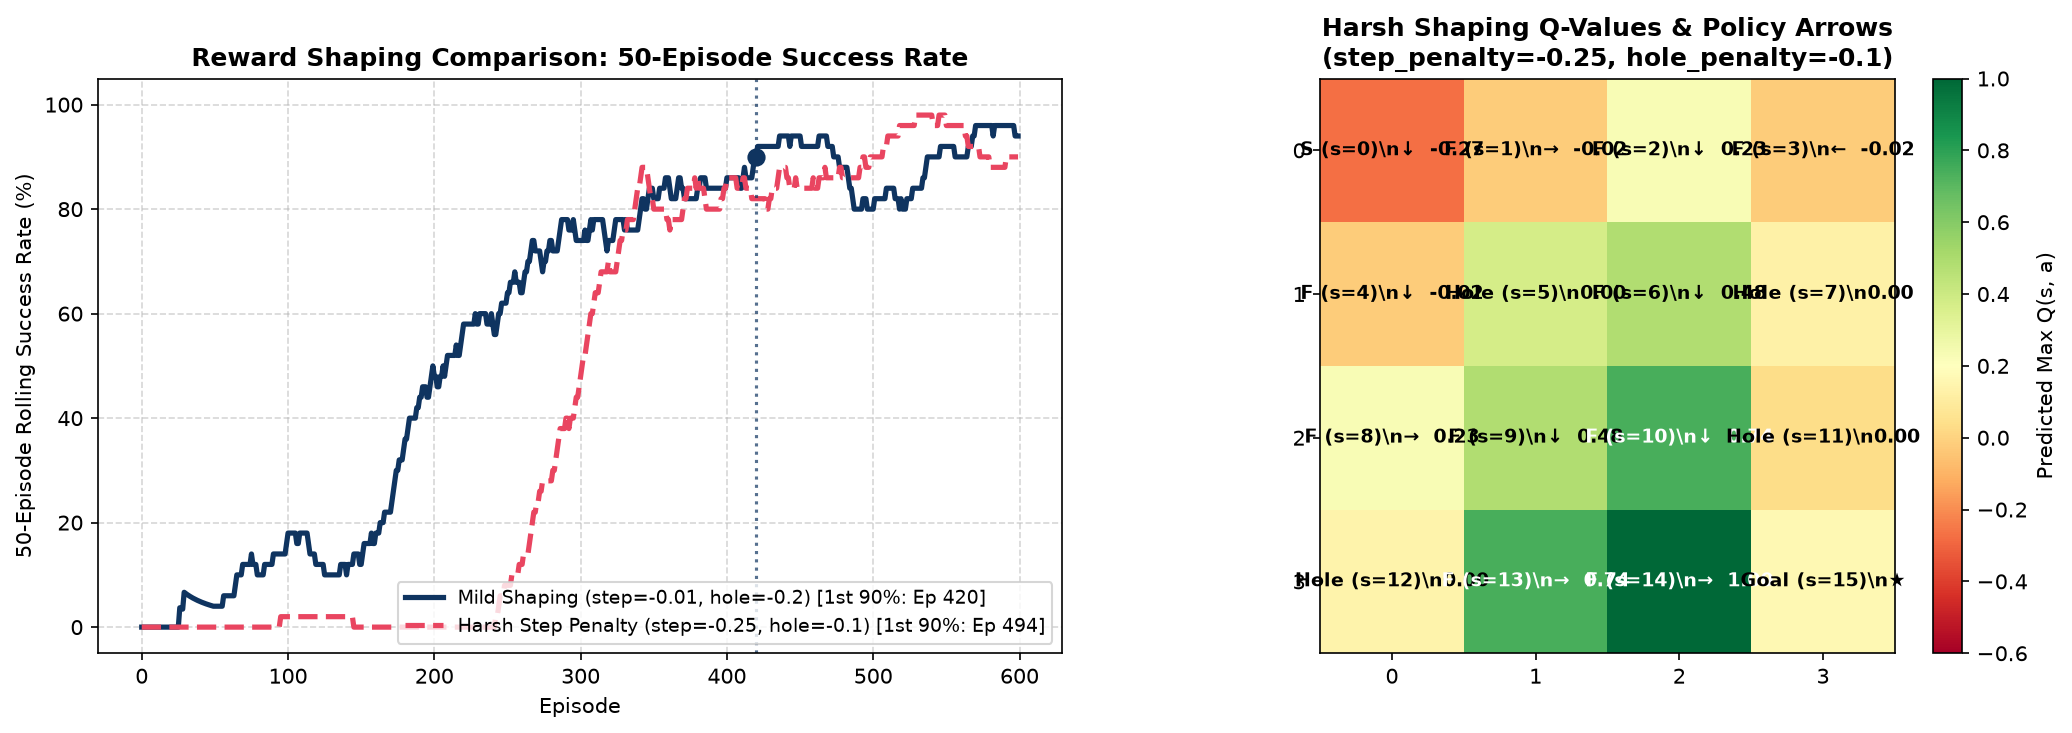

In [ ]:
# Visualization Dashboard for Exercise 3
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Rolling Success Rate
ax1 = axes[0]
roll_mild = [np.mean(r_mild[max(0, i-49):i+1]) * 100 for i in range(len(r_mild))]
roll_harsh = [np.mean(r_harsh[max(0, i-49):i+1]) * 100 for i in range(len(r_harsh))]
ax1.plot(roll_mild, color="#0f3460", linewidth=2.5, label=f"Mild Shaping (step=-0.01, hole=-0.2) [1st 90%: Ep {f90_mild}]")
ax1.plot(roll_harsh, color="#e94560", linewidth=2.5, linestyle="--", label=f"Harsh Step Penalty (step=-0.25, hole=-0.1) [1st 90%: Ep {f90_harsh}]")
if f90_mild:
    ax1.axvline(f90_mild, color="#0f3460", linestyle=":", alpha=0.7)
    ax1.scatter([f90_mild], [roll_mild[f90_mild-1]], color="#0f3460", s=60, zorder=5)
ax1.set_xlabel("Episode")
ax1.set_ylabel("50-Episode Rolling Success Rate (%)")
ax1.set_title("Reward Shaping Comparison: 50-Episode Success Rate", fontweight="bold")
ax1.set_ylim(-5, 105)
ax1.legend(loc="lower right", fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.5)

# Panel 2: Heatmap of Harsh Penalty Learned Values
ax2 = axes[1]
q_harsh = agent_harsh.get_all_q_values()
max_q_harsh = np.max(q_harsh, axis=1).reshape(4, 4)
best_act_harsh = np.argmax(q_harsh, axis=1).reshape(4, 4)
im = ax2.imshow(max_q_harsh, cmap="RdYlGn", vmin=-0.6, vmax=1.0)
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04, label="Predicted Max Q(s, a)")

grid_labels = [["S", "F", "F", "F"], ["F", "H", "F", "H"], ["F", "F", "F", "H"], ["H", "F", "F", "G"]]
arrow_map = {0: "←", 1: "↓", 2: "→", 3: "↑"}
for r in range(4):
    for c in range(4):
        tile = grid_labels[r][c]
        val = max_q_harsh[r, c]
        arrow = arrow_map[best_act_harsh[r, c]]
        s = r * 4 + c
        lbl = f"Hole (s={s})\n0.00" if tile == "H" else (f"Goal (s=15)\n★" if tile == "G" else f"{tile} (s={s})\n{arrow}  {val:.2f}")
        ax2.text(c, r, lbl, ha="center", va="center", color="black" if abs(val) < 0.5 else "white", fontweight="bold", fontsize=9)

ax2.set_xticks(range(4))
ax2.set_yticks(range(4))
ax2.set_title("Harsh Shaping Q-Values & Policy Arrows\n(step_penalty=-0.25, hole_penalty=-0.1)", fontweight="bold")

plt.tight_layout()
plt.show()


### Exercise 3: Custom Reward Shaping Design

#### 1. Episode where 50-episode rolling success first reaches 90%

* With `step_penalty = -0.01` and `hole_penalty = -0.2`:


* The 50-episode rolling success rate first hits 90% at episode 420 (later settling at around 94%).



---

#### 2. Why does setting step penalty = −0.25 and hole penalty = −0.1 trick the agent into jumping into the nearest hole at tile 5 instead of walking 6 steps to the goal?



##### A. Comparing Cumulative Returns

An RL agent simply maximizes expected discounted return, $G_t = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}$ (using $\gamma = 0.99$). Let's compare the payouts of trying to reach the goal versus jumping straight into Hole 5:

* Reaching the goal along the shortest path (6 steps: 5 regular steps + 1 goal step):


* Steps 1 to 5 cost $-0.25$ each.


* Step 6 yields the goal reward of $+1.0$.


* Total return:

$$G_{\text{goal}} = -0.25 (1 + 0.99 + 0.99^2 + 0.99^3 + 0.99^4) + 1.0 \times 0.99^5$$


$$G_{\text{goal}} = -0.25(4.901) + 0.951 = -1.225 + 0.951 = -0.274$$


* Even under a flawless run, the accumulated step penalties ($-1.225$) outweigh the final reward ($+0.951$), meaning a successful run still results in a net negative score.
* If the agent wanders for just one extra step (7 steps total), the return drops further:

$$-0.25(5.852) + 0.941 = -0.522$$




* Ending the run at Hole 5 (2 steps: $0 \to 1 \to 5$ or $0 \to 4 \to 5$):


* Step 1 incurs the regular step penalty of $-0.25$.


* Step 2 falls into Hole 5, receiving the penalty of $-0.10$ and terminating the episode immediately ($d = 1$, no further penalties).


* Total return:

$$G_{\text{hole}} = -0.25 + 0.99 \times (-0.10) = -0.349$$




* Once the agent is at tile 1 or tile 4, the choice is even clearer:
* Dropping directly into Hole 5 gives an immediate loss of $-0.10$.


* Trying to navigate the remaining 5 steps to the goal yields $-0.25(3.94) + 0.96 = -0.025$ only if completely optimal, but easily drops below $-0.25$ with even minor exploration.



##### B. Reward Shaping Side Effects (Reward Hacking)

* The agent optimizes purely for the numerical return specified by the reward function.


* Setting an aggressive step penalty ($-0.25$) alongside a mild terminal hole penalty ($-0.10$) makes staying alive far more costly than terminating early.


* During early training, exploratory paths often take 15 to 30 steps. A 20-step run accumulates an overwhelming loss of around $20 \times (-0.25) = -5.0$.


* The agent quickly learns that jumping into the nearest hole aborts the episode immediately and limits total losses to around $-0.35$.


* This illustrates a common failure mode in reward shaping: when intermediate penalties are poorly scaled, the agent optimizes for unintended shortcuts (in this case, deliberate suicide) instead of solving the target task.